# Day 3 — Planning & Decision-Making for Robots

Welcome to **Day 3** of the *UR5 AI Workshop*! 🚀

Today's focus is on **path planning** and **decision-making**, essential components in robotics.

### 🎯 Learning Objectives
- Understand path planning algorithms (BFS, Dijkstra, A*).
- Implement these algorithms to navigate a grid map.
- Learn the concept of **Finite State Machines (FSM)** for decision-making.
- Connect planning and FSM logic to simple UR5 robot actions.

## 🧩 Exercise 1 — Represent the Workspace as a Grid Graph

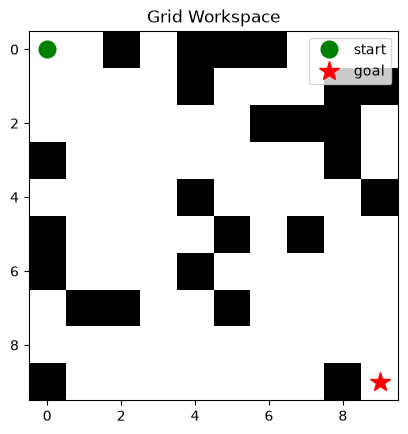

In [1]:
import numpy as np
import matplotlib.pyplot as plt

def create_grid(size=10, obstacle_prob=0.2):
    grid = np.zeros((size, size))
    obstacles = np.random.rand(size, size) < obstacle_prob
    grid[obstacles] = 1
    return grid

np.random.seed(1)          # same grid every run
grid = create_grid()
start, goal = (0, 0), (9, 9)
grid[start] = grid[goal] = 0  # make sure they're free

def show_grid(grid, path=None, title='Grid Workspace'):
    plt.imshow(grid, cmap='Greys')
    if path:
        plt.plot([p[1] for p in path], [p[0] for p in path], 'b-o', markersize=4)
    plt.plot(start[1], start[0], 'go', markersize=12, label='start')
    plt.plot(goal[1], goal[0], 'r*', markersize=15, label='goal')
    plt.title(title); plt.legend(); plt.show()

show_grid(grid)


## 🧩 Exercise 2 — Implement BFS and Dijkstra Algorithms

BFS:      length 19 | explored 74
Dijkstra: length 19 | explored 74


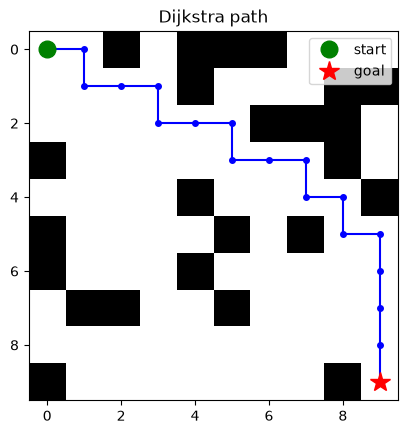

In [2]:
from heapq import heappush, heappop
from collections import deque

def neighbors(pos, grid):
    x, y = pos
    for dx, dy in [(0,1),(1,0),(-1,0),(0,-1)]:
        nx, ny = x+dx, y+dy
        if 0 <= nx < grid.shape[0] and 0 <= ny < grid.shape[1] and grid[nx, ny] == 0:
            yield (nx, ny)

def make_path(came_from, goal):
    if goal not in came_from:
        return None  # no path
    path = [goal]
    while came_from[path[-1]] is not None:
        path.append(came_from[path[-1]])
    return path[::-1]

def bfs(start, goal, grid):
    queue = deque([start])
    came_from = {start: None}
    while queue:
        current = queue.popleft()
        if current == goal:
            break
        for n in neighbors(current, grid):
            if n not in came_from:
                came_from[n] = current
                queue.append(n)
    return make_path(came_from, goal), len(came_from)

def dijkstra(start, goal, grid):
    heap = [(0, start)]
    came_from = {start: None}
    cost = {start: 0}
    while heap:
        c, current = heappop(heap)
        if current == goal:
            break
        for n in neighbors(current, grid):
            new_cost = c + 1  # every step costs 1
            if new_cost < cost.get(n, float('inf')):
                cost[n] = new_cost
                came_from[n] = current
                heappush(heap, (new_cost, n))
    return make_path(came_from, goal), len(came_from)

path, explored = bfs(start, goal, grid)
print('BFS:      length', len(path), '| explored', explored)
path, explored = dijkstra(start, goal, grid)
print('Dijkstra: length', len(path), '| explored', explored)
show_grid(grid, path, 'Dijkstra path')


## 🧩 Exercise 3 — Implement A* Algorithm

A*:       length 19 | explored 65


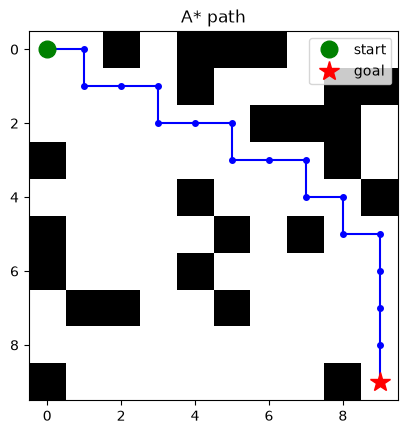

In [3]:
def heuristic(a, b):
    return abs(a[0]-b[0]) + abs(a[1]-b[1])

def astar(start, goal, grid):
    heap = [(0, start)]
    came_from = {start: None}
    cost = {start: 0}
    while heap:
        _, current = heappop(heap)
        if current == goal:
            break
        for n in neighbors(current, grid):
            new_cost = cost[current] + 1
            if new_cost < cost.get(n, float('inf')):
                cost[n] = new_cost
                came_from[n] = current
                heappush(heap, (new_cost + heuristic(n, goal), n))  # A* = cost so far + guess to goal
    return make_path(came_from, goal), len(came_from)

path, explored = astar(start, goal, grid)
print('A*:       length', len(path), '| explored', explored)
show_grid(grid, path, 'A* path')


## 🧩 Exercise 4 — Finite State Machines (FSM) for Decision-Making

In [4]:
class RobotFSM:
    # (state, event) -> next state
    transitions = {
        ('SEARCH', 'object_detected'): 'MOVE_TO_OBJECT',
        ('MOVE_TO_OBJECT', 'arrived'): 'GRASP',
        ('GRASP', 'grasped'): 'MOVE_TO_PLACE',
        ('MOVE_TO_PLACE', 'arrived'): 'PLACE',
        ('PLACE', 'released'): 'DONE',
    }
    def __init__(self):
        self.state = 'SEARCH'
    def next(self, event):
        new_state = self.transitions.get((self.state, event), self.state)  # unknown event -> stay
        print(f'{self.state} --{event}--> {new_state}')
        self.state = new_state
        return new_state

fsm = RobotFSM()
fsm.next('object_detected')
fsm.next('grasped')   # wrong event for this state -> stays
fsm.next('arrived')


SEARCH --object_detected--> MOVE_TO_OBJECT
MOVE_TO_OBJECT --grasped--> MOVE_TO_OBJECT
MOVE_TO_OBJECT --arrived--> GRASP


'GRASP'

## 🎓 Final Challenge — Combine Planning and FSM

Combine your A* planner and FSM logic to simulate a pick-and-place sequence:
1. Use A* to plan from start to object position.
2. Trigger FSM transitions to simulate grasp and move.
3. Plan path to placement location and simulate completion.

💡 *Optional:* visualize the full process using matplotlib animations.

SEARCH --object_detected--> MOVE_TO_OBJECT
path to object: 12 steps
MOVE_TO_OBJECT --arrived--> GRASP
GRASP --grasped--> MOVE_TO_PLACE
path to place: 12 steps
MOVE_TO_PLACE --arrived--> PLACE
PLACE --released--> DONE


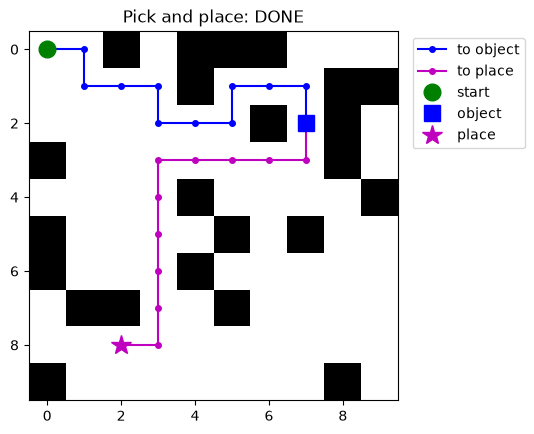

In [5]:
object_pos, place_pos = (2, 7), (8, 2)
grid[object_pos] = grid[place_pos] = 0

fsm = RobotFSM()
fsm.next('object_detected')

path1, _ = astar(start, object_pos, grid)        # 1. plan to the object
print('path to object:', len(path1), 'steps')
fsm.next('arrived')
fsm.next('grasped')                               # 2. grasp

path2, _ = astar(object_pos, place_pos, grid)    # 3. plan to the place location
print('path to place:', len(path2), 'steps')
fsm.next('arrived')
fsm.next('released')

plt.imshow(grid, cmap='Greys')
plt.plot([p[1] for p in path1], [p[0] for p in path1], 'b-o', markersize=4, label='to object')
plt.plot([p[1] for p in path2], [p[0] for p in path2], 'm-o', markersize=4, label='to place')
plt.plot(start[1], start[0], 'go', markersize=12, label='start')
plt.plot(object_pos[1], object_pos[0], 'bs', markersize=12, label='object')
plt.plot(place_pos[1], place_pos[0], 'm*', markersize=15, label='place')
plt.title(f'Pick and place: {fsm.state}'); plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left'); plt.show()


In [7]:
# Optional: drive URSim along the planned paths (grid cells -> 40 x 40 cm area of the table)
# Day 2 notebook must be disconnected first.
import math
from rtde_control import RTDEControlInterface
from rtde_receive import RTDEReceiveInterface

rtde_c = RTDEControlInterface('127.0.0.1')
rtde_r = RTDEReceiveInterface('127.0.0.1')

def cell_to_robot(cell):
    row, col = cell
    return -0.60 + row * 0.04, 0.20 - col * 0.04   # each cell is 4 cm

down = [0, math.pi, 0]
rtde_c.moveJ([-0.301, -1.528, 2.179, -2.221, -1.571, -1.872], 0.5, 0.5)  # start pose above the table
for path in [path1, path2]:
    for cell in path:
        X, Y = cell_to_robot(cell)
        rtde_c.moveL([X, Y, 0.20] + down, 0.25, 0.5)
    rtde_c.moveL([X, Y, 0.10] + down, 0.25, 0.5)   # down to pick / place
    rtde_c.moveL([X, Y, 0.20] + down, 0.25, 0.5)
print('done, tool at', [round(v, 3) for v in rtde_r.getActualTCPPose()[:3]])

rtde_c.stopScript()
rtde_c.disconnect()
rtde_r.disconnect()


done, tool at [-0.28, 0.12, 0.2]
